In [ ]:
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

In [ ]:
data = pd.read_csv("/content/data/drug.csv")
print(data.head())

   Age Sex      BP Cholesterol  Na_to_K   Drug
0   23   F    HIGH        HIGH   25.355  drugY
1   47   M     LOW        HIGH   13.093  drugC
2   47   M     LOW        HIGH   10.114  drugC
3   28   F  NORMAL        HIGH    7.798  drugX
4   61   F     LOW        HIGH   18.043  drugY


In [ ]:
X = data.drop("Drug", axis=1)
y = data["Drug"]

In [ ]:
categorical_columns = ["Sex", "BP", "Cholesterol"]

In [ ]:
preprocessor = ColumnTransformer(
    transformers=[
        ("categorical",
         OneHotEncoder(handle_unknown="ignore"),
         ["Sex", "BP", "Cholesterol"])
    ],
    remainder="passthrough",
    force_int_remainder_cols=False
)

In [ ]:
model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier",
     DecisionTreeClassifier(criterion="entropy", random_state=42))
])

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

In [ ]:
model.fit(X_train, y_train)

In [ ]:
y_pred = model.predict(X_test)

In [ ]:
accuracy = accuracy_score(y_test, y_pred)

print("\nActual Drugs:")
print(y_test.values)

print("\nPredicted Drugs:")
print(y_pred)

print("\nAccuracy:")
print(accuracy)

print("\nAccuracy in percentage:")
print(accuracy * 100, "%")


Actual Drugs:
['drugA' 'drugB' 'drugY' 'drugY' 'drugY' 'drugY' 'drugC' 'drugY' 'drugY'
 'drugX' 'drugX' 'drugY' 'drugC' 'drugX' 'drugA' 'drugX' 'drugY' 'drugC'
 'drugY' 'drugY' 'drugY' 'drugA' 'drugC' 'drugY' 'drugB' 'drugB' 'drugA'
 'drugB' 'drugC' 'drugX' 'drugY' 'drugB' 'drugX' 'drugA' 'drugY' 'drugX'
 'drugY' 'drugY' 'drugY' 'drugY' 'drugX' 'drugX' 'drugA' 'drugY' 'drugX'
 'drugX' 'drugX' 'drugX' 'drugY' 'drugX' 'drugY' 'drugY' 'drugX' 'drugX'
 'drugY' 'drugY' 'drugY' 'drugA' 'drugY' 'drugY']

Predicted Drugs:
['drugA' 'drugA' 'drugY' 'drugY' 'drugY' 'drugY' 'drugC' 'drugY' 'drugY'
 'drugX' 'drugX' 'drugY' 'drugC' 'drugX' 'drugA' 'drugX' 'drugY' 'drugC'
 'drugY' 'drugY' 'drugY' 'drugA' 'drugC' 'drugY' 'drugB' 'drugB' 'drugA'
 'drugB' 'drugC' 'drugX' 'drugY' 'drugB' 'drugX' 'drugA' 'drugY' 'drugX'
 'drugY' 'drugY' 'drugY' 'drugY' 'drugX' 'drugX' 'drugA' 'drugY' 'drugX'
 'drugX' 'drugX' 'drugX' 'drugY' 'drugX' 'drugY' 'drugY' 'drugX' 'drugX'
 'drugY' 'drugY' 'drugY' 'drugA' 'drugY' 

In [ ]:
patient = pd.DataFrame({
    "Age": [47],
    "Sex": ["M"],
    "BP": ["LOW"],
    "Cholesterol": ["HIGH"],
    "Na_to_K": [13.093]
})

prediction = model.predict(patient)

print("\nPredicted drug for the new patient:")
print(prediction[0])


Predicted drug for the new patient:
drugC


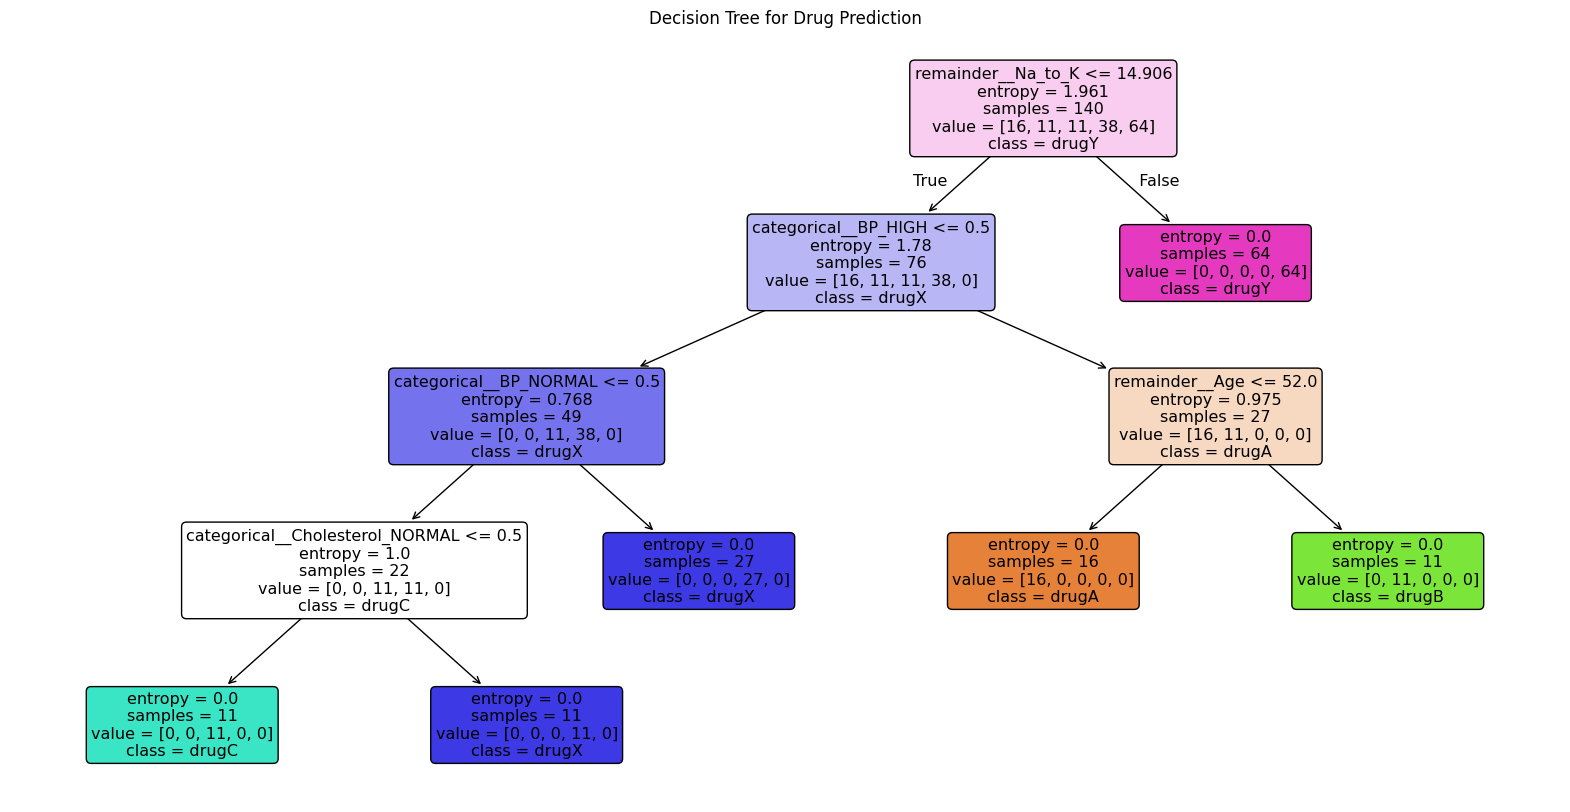

In [ ]:
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

tree_model = model.named_steps["classifier"]

feature_names = model.named_steps["preprocessor"].get_feature_names_out()

plt.figure(figsize=(20, 10))

plot_tree(
    tree_model,
    feature_names=feature_names,
    class_names=tree_model.classes_,
    filled=True,
    rounded=True
)

plt.title("Decision Tree for Drug Prediction")
plt.show()